# 01 — Data acquisition, validation and exploratory analysis

This notebook inspects the two Fama/French data vintages and the FRED VIX series supplied for the project. It does not download or overwrite source data. The canonical model run is `python run_pipeline.py`; this notebook focuses on data integrity, coverage and the volatility context.

**Sources:** Kenneth R. French Data Library (current CIZ-based daily five factors and December 2024 FIZ archive); FRED VIXCLS (CBOE VIX daily close).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'src' / 'volatility_project').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'volatility_project').exists():
    raise FileNotFoundError('Open this notebook from the project directory or one of its subdirectories.')
sys.path.insert(0, str(ROOT / 'src'))
from volatility_project.data import build_market_panel, parse_fama_french_zip, parse_fred_vix
RAW = ROOT / 'data' / 'raw'
CIZ_FILE = RAW / 'fama_french_5_factors_daily_ciz.csv'
FIZ_FILE = RAW / 'fama_french_5_factors_daily_fiz_2024.csv'
VIX_FILE = RAW / 'fred_vixcls.csv'
for path in (CIZ_FILE, FIZ_FILE, VIX_FILE):
    print(f'{path.name}: {path.exists()}')
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. See README for expected filenames.')

fama_french_5_factors_daily_ciz.csv: True
fama_french_5_factors_daily_fiz_2024.csv: True
fred_vixcls.csv: True


In [2]:
ciz = build_market_panel(CIZ_FILE, VIX_FILE)
fiz = build_market_panel(FIZ_FILE, VIX_FILE)
vix = parse_fred_vix(VIX_FILE)

coverage = pd.DataFrame([
    {'series':'Current CIZ market panel','rows':len(ciz),'start':ciz.index.min().date(),'end':ciz.index.max().date(),'missing_vix':int(ciz.vix.isna().sum()),'duplicate_dates':int(ciz.index.duplicated().sum())},
    {'series':'Dec-2024 FIZ archive panel','rows':len(fiz),'start':fiz.index.min().date(),'end':fiz.index.max().date(),'missing_vix':int(fiz.vix.isna().sum()),'duplicate_dates':int(fiz.index.duplicated().sum())},
    {'series':'FRED VIX source','rows':len(vix),'start':vix.index.min().date(),'end':vix.index.max().date(),'missing_vix':0,'duplicate_dates':int(vix.index.duplicated().sum())},
])
display(coverage)
print('CIZ/FIZ common dates:', len(ciz.index.intersection(fiz.index)))
print('CIZ columns:', list(ciz.columns))
print('CIZ return summary (decimal):')
display(ciz['market_return'].describe().to_frame().T)

,series,rows,start,end,missing_vix,duplicate_dates
0,Current CIZ market panel,9254,1990-01-02,2026-09-30,3,0
1,Dec-2024 FIZ archive panel,8817,1990-01-02,2024-12-31,3,0
2,FRED VIX source,9323,1990-01-02,2026-11-23,0,0


CIZ/FIZ common dates: 8817
CIZ columns: ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF', 'vix', 'mkt_rf', 'smb', 'hml', 'rmw', 'cma', 'rf', 'market_excess', 'market_return', 'vix_decimal', 'vix_implied_variance']
CIZ return summary (decimal):


,count,mean,std,min,25%,50%,75%,max
market_return,9254.0,0.000479,0.011363,-0.12,-0.0043,0.0007,0.0058,0.1136


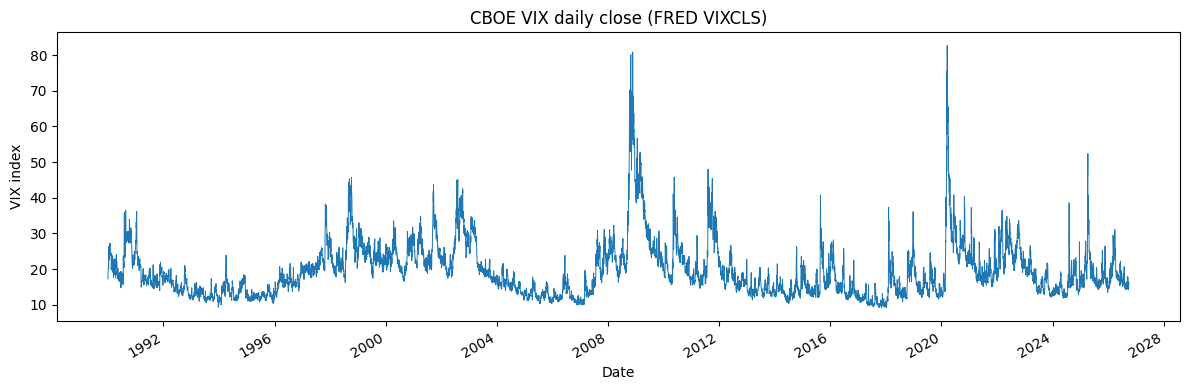

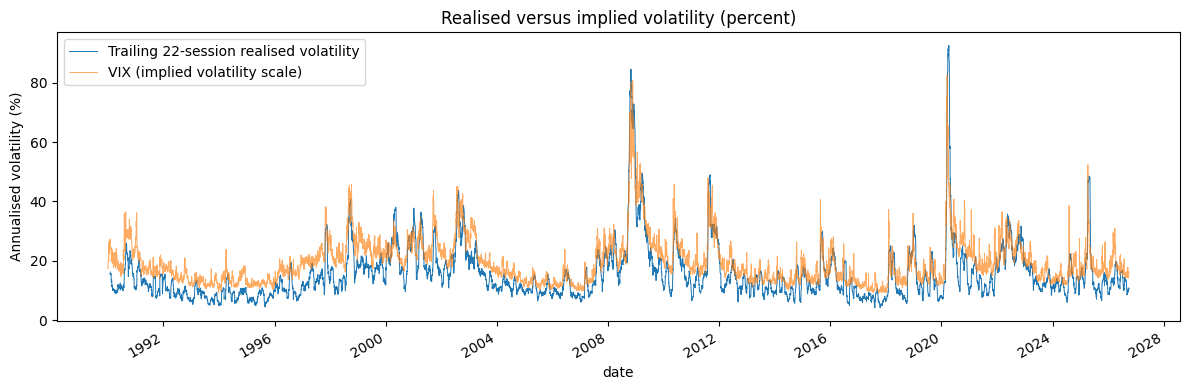

Correlation of VIX with trailing 22-session realised volatility: 0.8557


In [3]:
# VIX is a predictor and is left-joined to market returns. Missing VIX values
# must not delete market sessions or shift the forward realised-variance target.
fig, ax = plt.subplots(figsize=(12, 4))
ciz['vix'].plot(ax=ax, lw=0.7)
ax.set(title='CBOE VIX daily close (FRED VIXCLS)', ylabel='VIX index')
ax.set_xlabel('Date')
plt.tight_layout()
plt.show()

trailing_rv = np.sqrt(252 * ciz['market_return'].pow(2).rolling(22).mean())
fig, ax = plt.subplots(figsize=(12, 4))
trailing_rv.mul(100).plot(ax=ax, lw=0.7, label='Trailing 22-session realised volatility')
(ciz['vix'] / 100 * 100).plot(ax=ax, lw=0.7, alpha=0.65, label='VIX (implied volatility scale)')
ax.set(title='Realised versus implied volatility (percent)', ylabel='Annualised volatility (%)')
ax.legend()
plt.tight_layout()
plt.show()

print('Correlation of VIX with trailing 22-session realised volatility:', round(ciz['vix'].corr(trailing_rv * 100), 4))

## Data interpretation and caveats

- The CIZ source file ends on 30 September 2026; the VIX file itself extends further, but the joined return/volatility analysis cannot extend beyond the market-return file.
- FIZ and CIZ are separate publisher data vintages. They are compared on common historical dates rather than treating the format change as a simple date-based break.
- The current CIZ file documents a change in the one-month Treasury-bill proxy used for `RF` from June 2024. This matters for vintage comparisons and risk-free accrual.
- VIX is S&P 500 option-implied volatility, while the market-return target is based on the broader Fama/French US market portfolio.